<a href="https://colab.research.google.com/github/SergeiVKalinin/Paper_Notebooks/blob/main/VAE_Walls/Main_03_Alternative_Objectives.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Main 03 — Alternative learning objectives (Figures 8 and 9)

**Figure 8** consists of analytical comparisons computed here: a conditional-mean VAE, a two-prototype flow, a prescribed mixture prior, and a restricted Gaussian-process evidence model.

**Figure 9** can be *studied* with an independently trained benchmark, but the original paper's MNIST latent coordinates and checkpoints are unavailable. The lightweight experiment below is therefore a **new reproducible example**, not a pixel-for-pixel or quantitative reproduction of the original Figure 9. Its GP objective is an exact **minibatch** evidence loss, not the paper's sparse variational GP. Do not substitute the resulting panels for the manuscript's Figure 9 without separately verifying the protocol.

Only separate PNG plots are written to `/content`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# All user-visible output is PNG; nothing is cached or exported in other formats.
OUTPUT = Path('/content') if Path('/content').exists() else Path.cwd()
FAST_MODE = False       # False: use the longer, publication-scale calculations.
DPI = 180 if FAST_MODE else 300

def save_panel(fig, filename):
    fig.savefig(OUTPUT / filename, dpi=DPI, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved', OUTPUT / filename)

import math
from scipy import optimize, stats
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.neighbors import KNeighborsClassifier
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Figure 8 — analytical panels

The two-cluster GP evidence is computed exactly from its symmetric and antisymmetric eigenvalues, keeping the signal amplitude and observation noise fixed. For large target differences, the search can terminate at an **upper search bound**, which is not a physically identified detached separation.

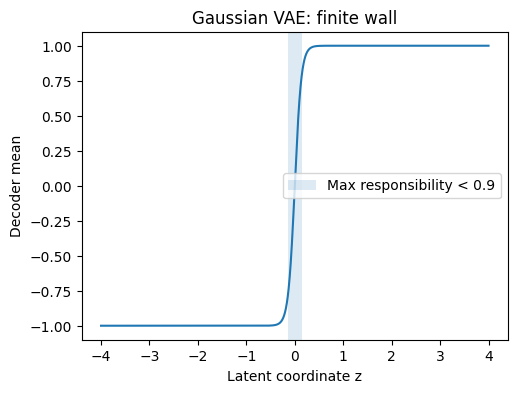

Saved /content/Fig08_a_vae_wall.png


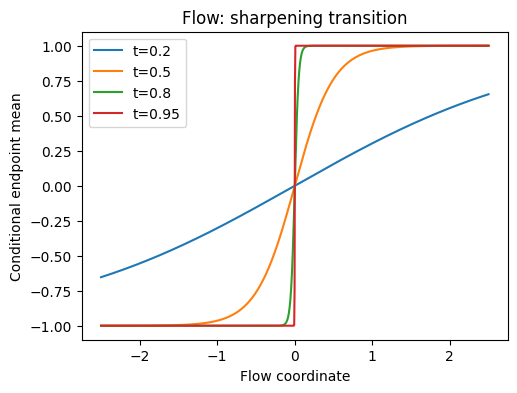

Saved /content/Fig08_b_flow_profiles.png


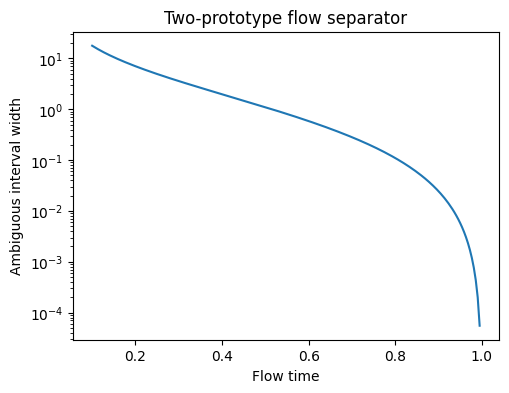

Saved /content/Fig08_b_flow_width.png


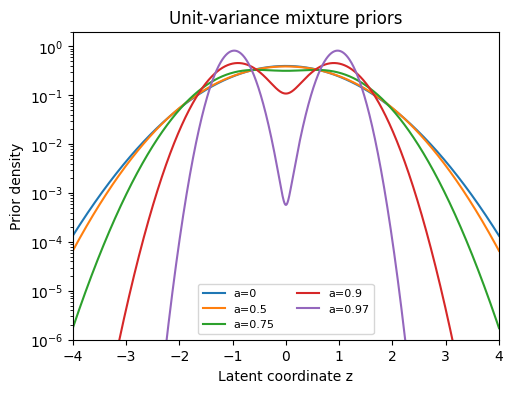

Saved /content/Fig08_c_prescribed_priors.png


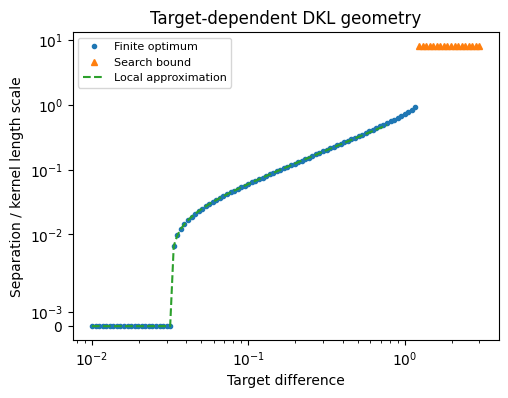

Saved /content/Fig08_d_dkl_distance.png


In [2]:
# (a) Conditional-mean decoder with two equally likely prototypes.
z=np.linspace(-4,4,3000)
m=1.5;s=.45;ell=s*s/m
border=ell*np.arctanh(.8)
fig,ax=plt.subplots(figsize=(5.5,4))
ax.plot(z,np.tanh(z/ell))
ax.axvspan(-border,border,alpha=.15,label='Max responsibility < 0.9')
ax.set(xlabel='Latent coordinate z',ylabel='Decoder mean',title='Gaussian VAE: finite wall')
ax.legend();save_panel(fig,'Fig08_a_vae_wall.png')

# (b) Conditional endpoint mean of the two-prototype flow-matching construction.
x=np.linspace(-2.5,2.5,1000)
fig,ax=plt.subplots(figsize=(5.5,4))
for t in [.2,.5,.8,.95]:
    ax.plot(x,np.tanh(t*x/(1-t)**2),label=f't={t:g}')
ax.set(xlabel='Flow coordinate',ylabel='Conditional endpoint mean',title='Flow: sharpening transition')
ax.legend();save_panel(fig,'Fig08_b_flow_profiles.png')

# Additional control: ambiguous interval shrinks to the singular endpoint.
t=np.linspace(.1,.995,200)
width=2*(1-t)**2/t*np.arctanh(.8)
fig,ax=plt.subplots(figsize=(5.5,4))
ax.semilogy(t,width)
ax.set(xlabel='Flow time',ylabel='Ambiguous interval width',title='Two-prototype flow separator')
save_panel(fig,'Fig08_b_flow_width.png')

# (c) These are prescribed priors, not learned-prior training.
fig,ax=plt.subplots(figsize=(5.5,4))
for a in [0,.5,.75,.9,.97]:
    sigma=np.sqrt(1-a*a)
    p=.5*stats.norm.pdf(z,-a,sigma)+.5*stats.norm.pdf(z,a,sigma)
    ax.semilogy(z,p,label=f'a={a:g}')
ax.set(xlim=(-4,4),ylim=(1e-6,2),xlabel='Latent coordinate z',ylabel='Prior density',title='Unit-variance mixture priors')
ax.legend(ncol=2,fontsize=8)
save_panel(fig,'Fig08_c_prescribed_priors.png')

def gp_nll(distance, delta, n=20, signal=2.5, noise=.01):
    c=np.exp(-distance*distance/2)
    va=n*signal*(1-c)+noise
    vs=n*signal*(1+c)+noise
    return n*delta*delta/(4*va)+.5*np.log(va)+.5*np.log(vs)

def optimal_distance(delta):
    grid=np.r_[0,np.geomspace(1e-6,8,160)]
    values=np.array([gp_nll(d,delta) for d in grid])
    i=values.argmin()
    if 0<i<len(grid)-1:
        refined=optimize.minimize_scalar(lambda v:gp_nll(v,delta),bounds=(grid[i-1],grid[i+1]),method='bounded')
        return refined.x if refined.fun<values[i] else grid[i]
    return grid[i]

# (d) Exact evidence minimization within the specified search interval.
delta=np.geomspace(.01,3,110)
distance=np.array([optimal_distance(v) for v in delta])
approx=np.sqrt(np.maximum(delta**2-2*.01/20,0)/2.5)
fig,ax=plt.subplots(figsize=(5.5,4))
boundary=distance>=7.99
ax.semilogx(delta[~boundary],distance[~boundary],'o',ms=3,label='Finite optimum')
ax.semilogx(delta[boundary],distance[boundary],'^',ms=4,label='Search bound')
mask=approx<.5
ax.semilogx(delta[mask],approx[mask],'--',label='Local approximation')
ax.set_yscale('symlog',linthresh=.005)
ax.set(xlabel='Target difference',ylabel='Separation / kernel length scale',title='Target-dependent DKL geometry')
ax.legend(fontsize=8)
save_panel(fig,'Fig08_d_dkl_distance.png')

## Figure 9 — fresh MNIST test of target-shaped geometry

A small, clearly identified *new* training experiment contrasts (i) a reconstruction-oriented VAE, (ii) a target-only deep kernel, and (iii) a hybrid objective.

The scalar target is mean ink density. Because this is not the original saved training protocol, it produces **illustrative new plots only**. The sections below deliberately omit any historical five-seed values that cannot be reconstructed from raw saved samples.

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.75MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.77MB/s]


vae 1 complete
vae 2 complete
vae 3 complete
vae 4 complete
vae 5 complete
vae 6 complete
vae 7 complete
vae 8 complete
vae 9 complete
vae 10 complete
vae 11 complete
vae 12 complete
vae 13 complete
vae 14 complete
vae 15 complete
vae 16 complete
vae 17 complete
vae 18 complete
vae 19 complete
vae 20 complete
dkl 1 complete
dkl 2 complete
dkl 3 complete
dkl 4 complete
dkl 5 complete
dkl 6 complete
dkl 7 complete
dkl 8 complete
dkl 9 complete
dkl 10 complete
dkl 11 complete
dkl 12 complete
dkl 13 complete
dkl 14 complete
dkl 15 complete
dkl 16 complete
dkl 17 complete
dkl 18 complete
dkl 19 complete
dkl 20 complete
hybrid 1 complete
hybrid 2 complete
hybrid 3 complete
hybrid 4 complete
hybrid 5 complete
hybrid 6 complete
hybrid 7 complete
hybrid 8 complete
hybrid 9 complete
hybrid 10 complete
hybrid 11 complete
hybrid 12 complete
hybrid 13 complete
hybrid 14 complete
hybrid 15 complete
hybrid 16 complete
hybrid 17 complete
hybrid 18 complete
hybrid 19 complete
hybrid 20 complete


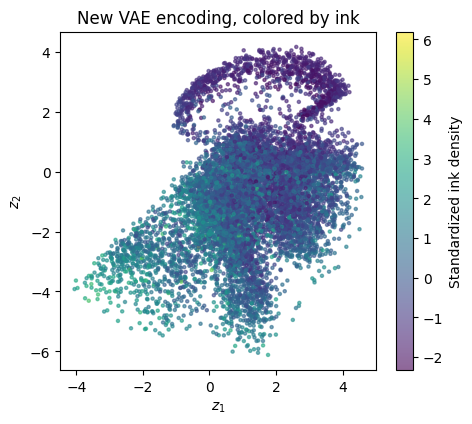

Saved /content/Fig09_new_vae_ink_latent.png


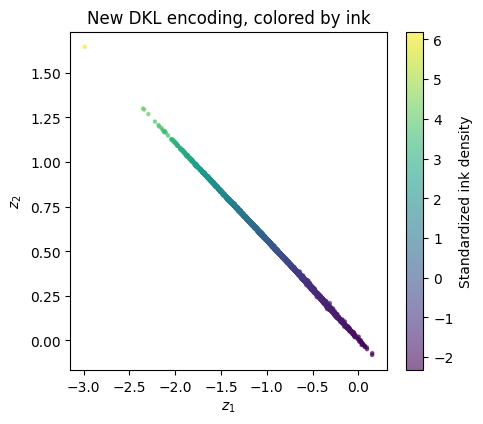

Saved /content/Fig09_new_dkl_ink_latent.png


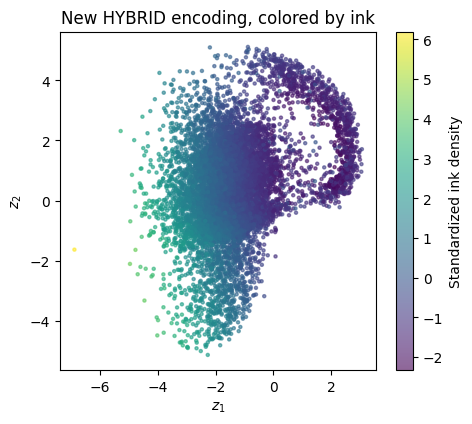

Saved /content/Fig09_new_hybrid_ink_latent.png


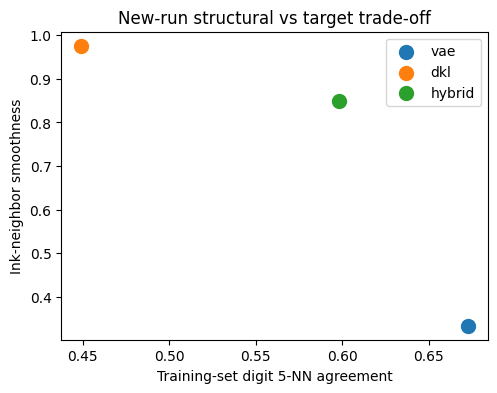

Saved /content/Fig09_new_structure_target_tradeoff.png


In [3]:
from torchvision.datasets import MNIST
mnist=MNIST(root='/tmp/vae_mnist',train=True,download=True)
X=(mnist.data.numpy().reshape(-1,784)/255.).astype('float32')
y=mnist.targets.numpy()
rng=np.random.default_rng(31)
idx=rng.choice(len(X),size=1600 if FAST_MODE else 10000,replace=False)
X=X[idx];y=y[idx]
ink=X.mean(axis=1);ink=(ink-ink.mean())/(ink.std()+1e-8)

class Feature(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(784,128),nn.ReLU(),nn.Linear(128,2))
    def forward(self,x):return self.net(x)

class Joint(nn.Module):
    def __init__(self,kind):
        super().__init__()
        self.kind=kind
        self.features=Feature()
        self.logvar=nn.Linear(2,2)
        self.decoder=nn.Sequential(nn.Linear(2,128),nn.ReLU(),nn.Linear(128,784))
    def forward(self,x):
        mu=self.features(x)
        lv=self.logvar(mu).clamp(-10,6)
        z=mu+torch.randn_like(mu)*torch.exp(.5*lv)
        return mu,lv,self.decoder(z)

def minibatch_gp_nll(z,y,noise=.08):
    # Differentiable exact GP evidence on the CURRENT minibatch, not a full-data GP.
    dist=torch.cdist(z,z).square()
    K=torch.exp(-.5*dist)+noise*torch.eye(len(z),device=z.device)
    L=torch.linalg.cholesky(K+1e-5*torch.eye(len(z),device=z.device))
    yc=(y-y.mean()).unsqueeze(1)
    alpha=torch.cholesky_solve(yc,L)
    return (.5*(yc*alpha).sum()+torch.log(torch.diag(L)).sum())/len(z)

def train_variant(kind,seed=17):
    torch.manual_seed(seed)
    model=Joint(kind).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=.001)
    arr=torch.tensor(X,device=DEVICE);target=torch.tensor(ink,device=DEVICE)
    batch_size=96
    for epoch in range(2 if FAST_MODE else 20):
        for ids in torch.randperm(len(arr),device=DEVICE).split(batch_size):
            xb=arr[ids];yb=target[ids]
            if len(ids)<10:continue
            mu,lv,recon=model(xb)
            rec=F.binary_cross_entropy_with_logits(recon,xb,reduction='sum')/len(ids)
            kl=(-.5*(1+lv-mu.square()-lv.exp()).sum())/len(ids)
            gp=minibatch_gp_nll(mu,yb)
            loss={'vae': rec+kl, 'dkl': 25*gp, 'hybrid': rec+kl+5*gp}[kind]
            opt.zero_grad();loss.backward();opt.step()
        print(kind,epoch+1,'complete')
    model.eval()
    with torch.no_grad(): z=model.features(arr).cpu().numpy()
    return model,z

results={kind:train_variant(kind) for kind in ['vae','dkl','hybrid']}
for kind,(model,z) in results.items():
    fig,ax=plt.subplots(figsize=(5.1,4.4))
    sc=ax.scatter(z[:,0],z[:,1],c=ink,s=5,cmap='viridis',alpha=.6)
    ax.set(xlabel='$z_1$',ylabel='$z_2$',title=f'New {kind.upper()} encoding, colored by ink')
    fig.colorbar(sc,ax=ax,label='Standardized ink density')
    save_panel(fig,f'Fig09_new_{kind}_ink_latent.png')

# An explicitly computed structural/target trade-off from the SAME new runs.
from sklearn.neighbors import NearestNeighbors
records=[]
for kind,(model,z) in results.items():
    knn=KNeighborsClassifier(n_neighbors=5).fit(z,y)
    digit_acc=(knn.predict(z)==y).mean() # descriptive training-set diagnostic; not held-out accuracy
    neighbors=NearestNeighbors(n_neighbors=6).fit(z).kneighbors(z,return_distance=False)[:,1:]
    local=np.abs(ink[:,None]-ink[neighbors]).mean()
    random=np.abs(ink[:,None]-ink[rng.integers(len(ink),size=neighbors.shape)]).mean()
    records.append((kind,digit_acc,1-local/random))
fig,ax=plt.subplots(figsize=(5.5,4))
for name,acc,smooth in records:
    ax.scatter(acc,smooth,s=100,label=name)
ax.set(xlabel='Training-set digit 5-NN agreement',ylabel='Ink-neighbor smoothness',title='New-run structural vs target trade-off')
ax.legend();save_panel(fig,'Fig09_new_structure_target_tradeoff.png')